### Goal
Dive into reducers,which specify how state updates are performed on specific keys/channels in the state schema

In [18]:
from operator import add
from typing import Annotated, TypedDict

from IPython.display import Image, display
from langgraph.errors import InvalidUpdateError
from langgraph.graph import END, START, StateGraph


In [3]:
class State(TypedDict):
    foo: int

In [4]:
def node_1(state):
    print("---node 1----")
    return {"foo": state["foo"] + 1}

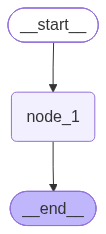

In [12]:
builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", END)
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
graph.invoke({"foo": 1})

---node 1----


{'foo': 2}

In [11]:
def node_2(state):
    print("---node 2---")
    return {"foo": state["foo"] + 1}


def node_3(state):
    print("---node 2---")
    return {"foo": state["foo"] + 1}

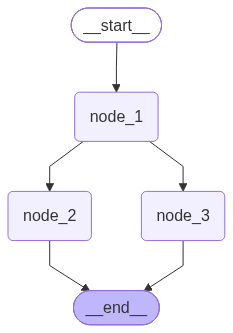

In [15]:
builder_1 = StateGraph(State)
builder_1.add_node("node_1", node_1)
builder_1.add_node("node_2", node_2)
builder_1.add_node("node_3", node_3)
builder_1.add_edge(START, "node_1")
builder_1.add_edge("node_1", "node_2")
builder_1.add_edge("node_1", "node_3")
builder_1.add_edge("node_2", END)
builder_1.add_edge("node_3", END)
graph_1 = builder_1.compile()
display(Image(graph_1.get_graph().draw_mermaid_png()))

- By default, whenever a field value in the class is invoked, the default value is overridden.
- In graph_1, node 2 and node 3 run in parallel and the state is updated concurrently by both nodes, which causes an InvalidUpdateError
-  This can be fixed by using reducers 

In [17]:
try:
    graph_1.invoke({"foo": 1})
except InvalidUpdateError as e:
    print("Error occured", e)

---node 1----
---node 2---
---node 2---
Error occured At key 'foo': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_CONCURRENT_GRAPH_UPDATE


### *Reducers*
- __Reducers__ gives us a general way to address the problem we encountered above 
- They specify how to perform updates 
- *Annotated* type can be used to specify the reducer function 
- For example, the following code will append the returned value rather than overwriting the existing state value 

In [37]:
class NewState(TypedDict):
    foo: Annotated[list[int], add]

In [52]:
def node_1(state: NewState):
    print("---node 1----")
    return {"foo": [state["foo"][0] + 1]}

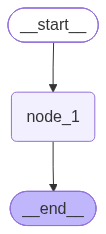

In [55]:
builder_2 = StateGraph(NewState)
builder_2.add_node("node_1", node_1)
builder_2.add_edge(START, "node_1")
graph_2 = builder_2.compile()
display(Image(graph_2.get_graph().draw_mermaid_png()))

In [57]:
graph_2.invoke({"foo": [0, 1]})

---node 1----


{'foo': [0, 1, 1]}

In [61]:
def node_1(state: NewState):
    print("---node 1----")
    return {"foo": [state["foo"][-1] + 1]}


def node_2(state: NewState):
    print("---node 2----")
    return {"foo": [state["foo"][-1] + 1]}


def node_3(state: NewState):
    print("---node 3----")
    return {"foo": [state["foo"][-1] + 1]}


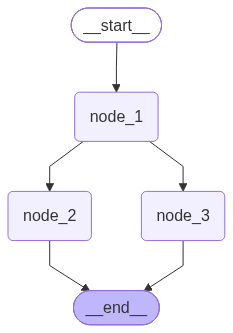

In [62]:
builder_3 = StateGraph(NewState)
builder_3.add_node("node_1", node_1)
builder_3.add_node("node_2", node_2)
builder_3.add_node("node_3", node_3)
builder_3.add_edge(START, "node_1")
builder_3.add_edge("node_1", "node_2")
builder_3.add_edge("node_1", "node_3")
graph_3 = builder_3.compile()
display(Image(graph_3.get_graph().draw_mermaid_png()))

In [75]:
for chunk in graph_3.stream({"foo": [1]}, stream_mode="values"):
    print(chunk)

{'foo': [1]}
---node 1----
{'foo': [1, 2]}
---node 2----
---node 3----
{'foo': [1, 2, 3, 3]}


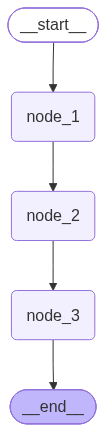

In [67]:
builder_4 = StateGraph(NewState)
builder_4.add_node("node_1", node_1)
builder_4.add_node("node_2", node_2)
builder_4.add_node("node_3", node_3)
builder_4.add_edge(START, "node_1")
builder_4.add_edge("node_1", "node_2")
builder_4.add_edge("node_2", "node_3")
graph_4 = builder_4.compile()
display(Image(graph_4.get_graph().draw_mermaid_png()))


In [71]:
for chunk in graph_4.stream({"foo": [1]}, stream_mode="values"):
    print(chunk)

{'foo': [1]}
---node 1----
{'foo': [1, 2]}
---node 2----
{'foo': [1, 2, 3]}
---node 3----
{'foo': [1, 2, 3, 4]}


In [72]:
try:
    graph_4.invoke({"foo": None})
except TypeError as e:
    print(e)

can only concatenate list (not "NoneType") to list


### *Custom Reducers*

In [74]:
def reduce_list(left: list | None, right: list | None) -> list:
    if not right:
        right = []
    if not left:
        left = []
    return left + right

In [78]:
class DefaultState(TypedDict):
    foo: Annotated[list[int], reduce_list]

In [79]:
def node_1(state: DefaultState):
    print("---node 1----")
    return {"foo": [state["foo"] + [1]]}


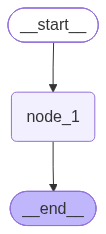

In [80]:
builder_5 = StateGraph(DefaultState)
builder_5.add_node("node_1", node_1)
builder_5.add_edge(START, "node_1")
graph_5 = builder_5.compile()
display(Image(graph_5.get_graph().draw_mermaid_png()))

In [81]:
graph_5.invoke({"foo": None})

---node 1----


{'foo': [[1]]}